
── Downloading data ──

── Scaling Law Test (DJIA) ──
  Scale                     Expected σ    Actual σ     Ratio
  --------------------------------------------------------
  Daily (baseline)             1.1093%     1.1093%     1.000
  Weekly  (√5  days)           2.4805%     2.3271%     2.098
  Monthly (√21 days)           5.0835%     4.2502%     3.831
  Quarterly(√63 days)          8.8049%     7.7203%     6.959

── Scaling Law Test (Nasdaq) ──
  Scale                     Expected σ    Actual σ     Ratio
  --------------------------------------------------------
  Daily (baseline)             1.4632%     1.4632%     1.000
  Weekly  (√5  days)           3.2718%     3.0503%     2.085
  Monthly (√21 days)           6.7052%     6.3274%     4.324
  Quarterly(√63 days)         11.6137%    12.1695%     8.317

  Saved fig1_distributions.png
  Saved fig2_autocorrelation.png
  Saved fig3_scaling_law.png
  Saved fig4_volatility_clustering.png

    ✓ MMM
    ✓ AXP
    ✓ BA
    ✓ CAT
    ✓ CVX
 

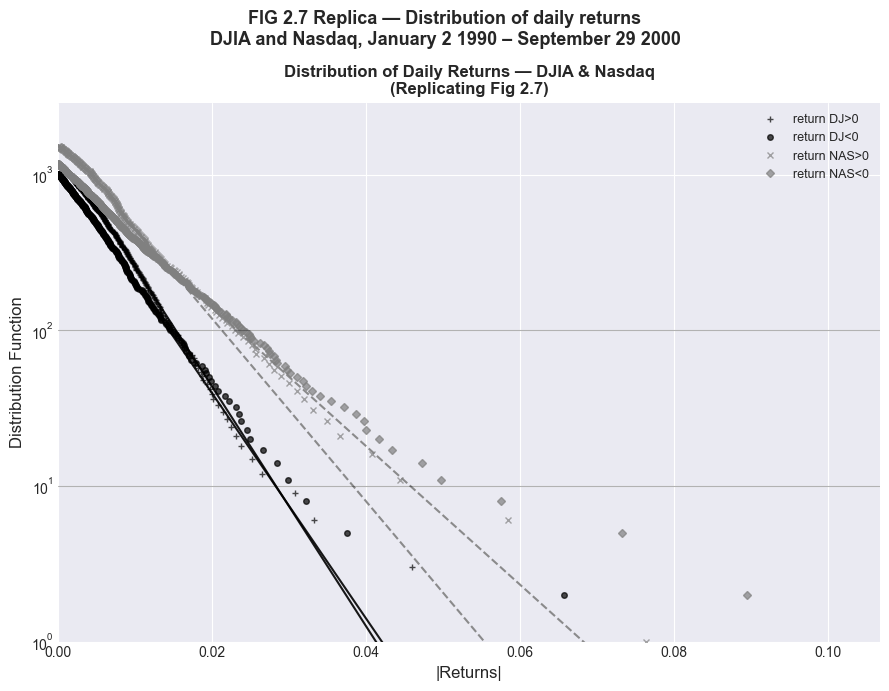

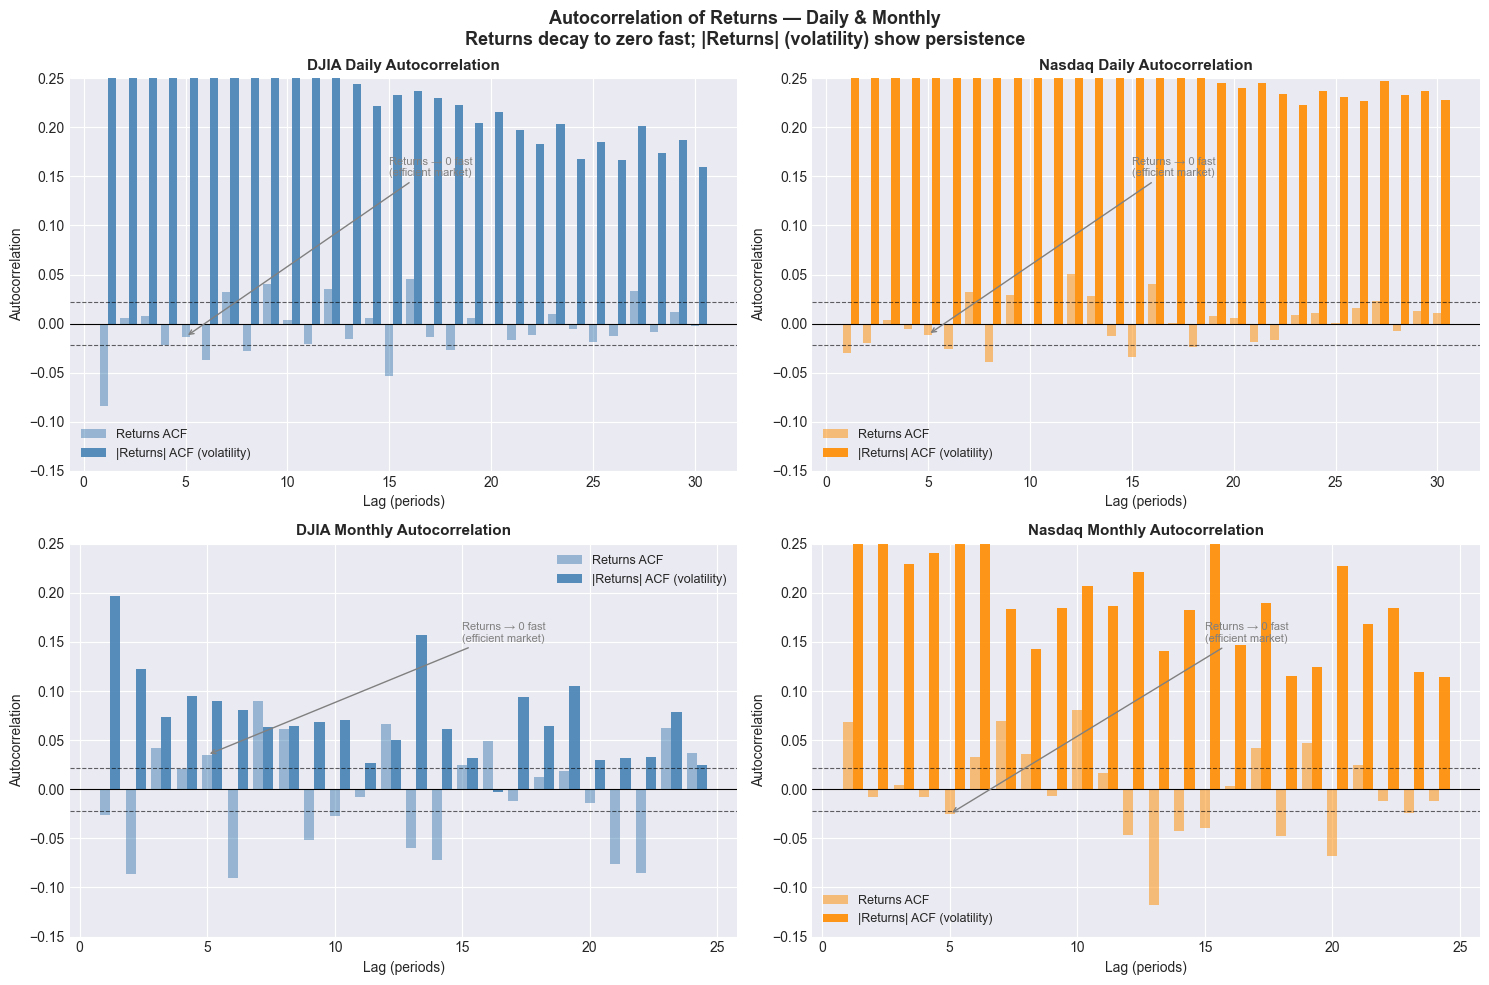

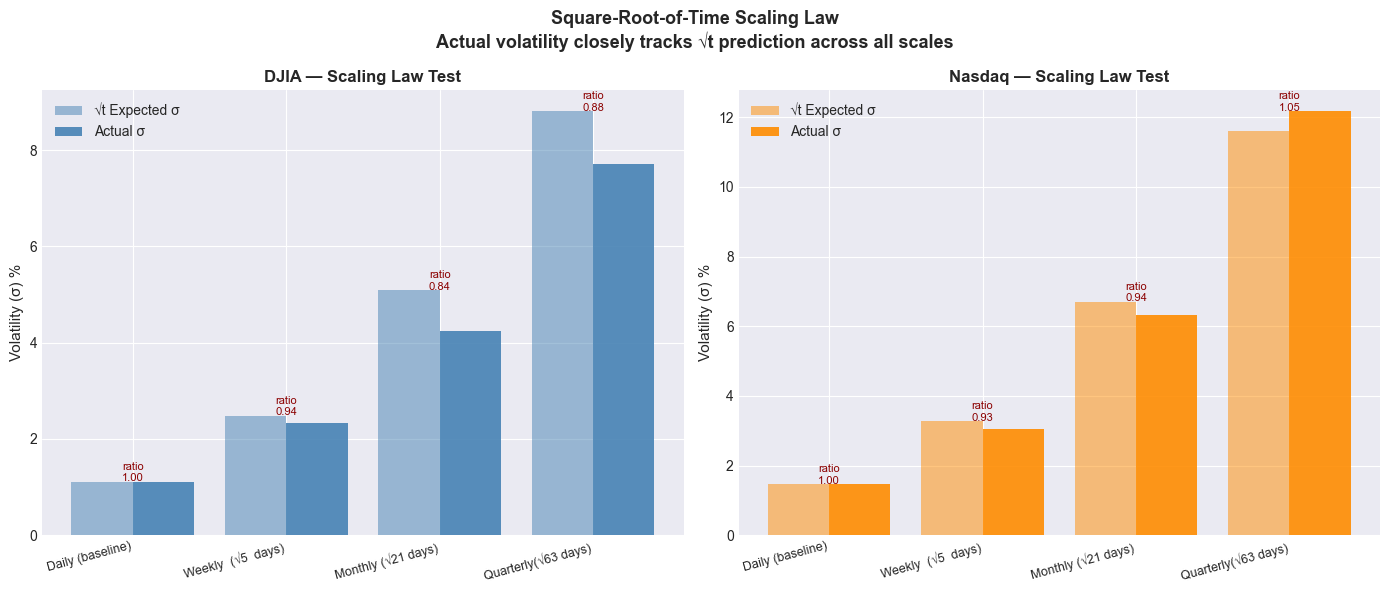

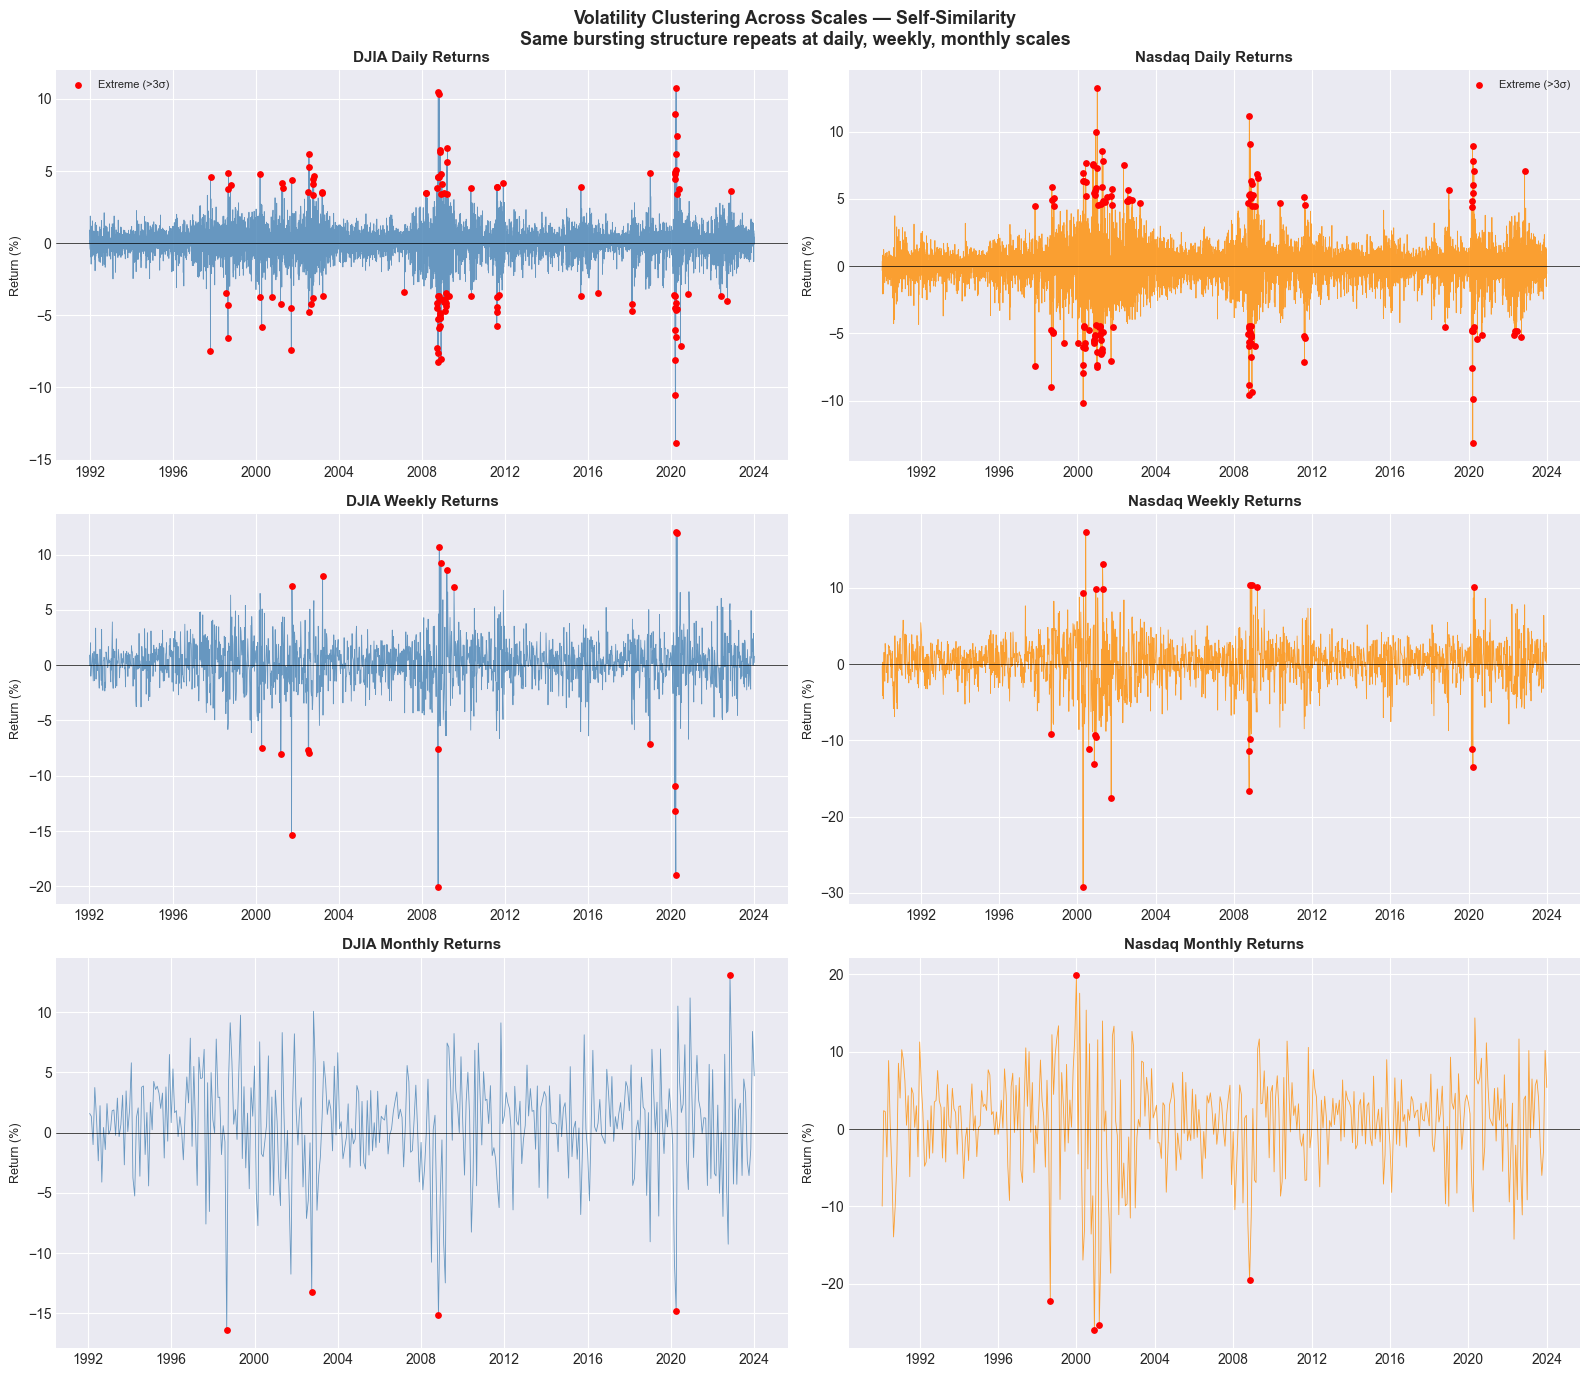

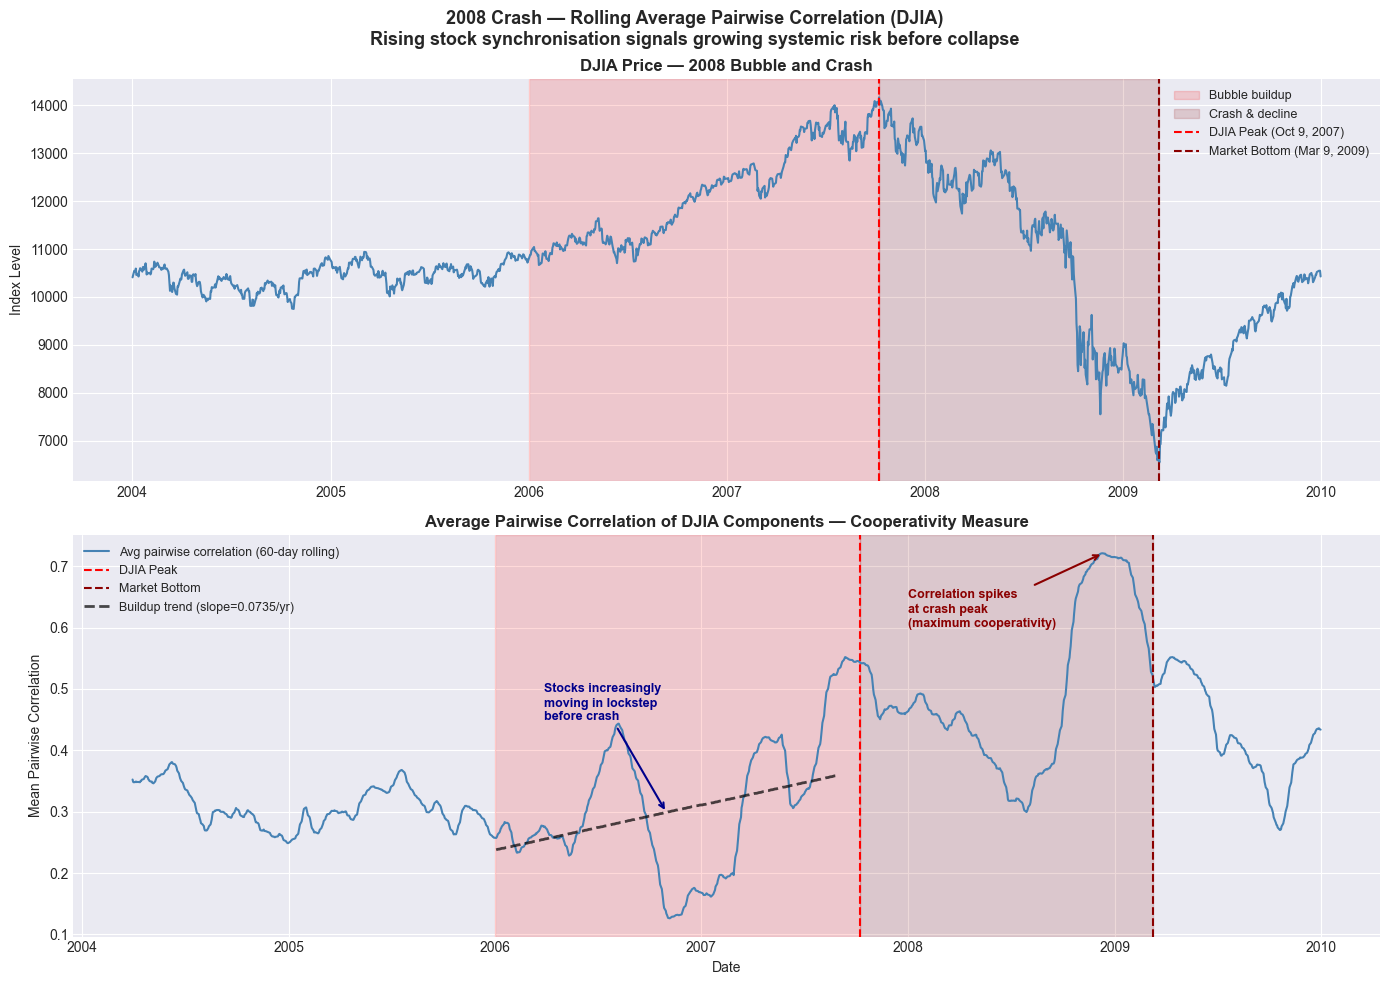

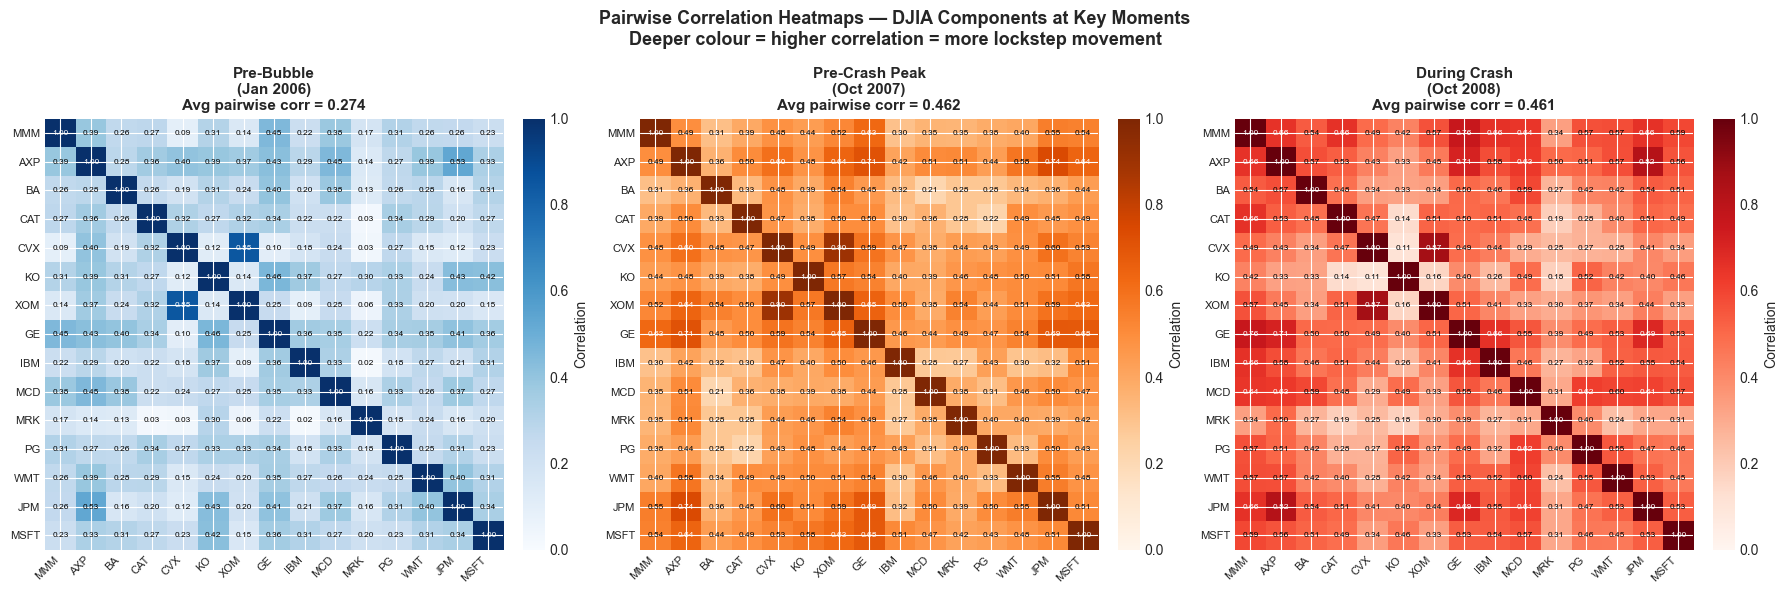

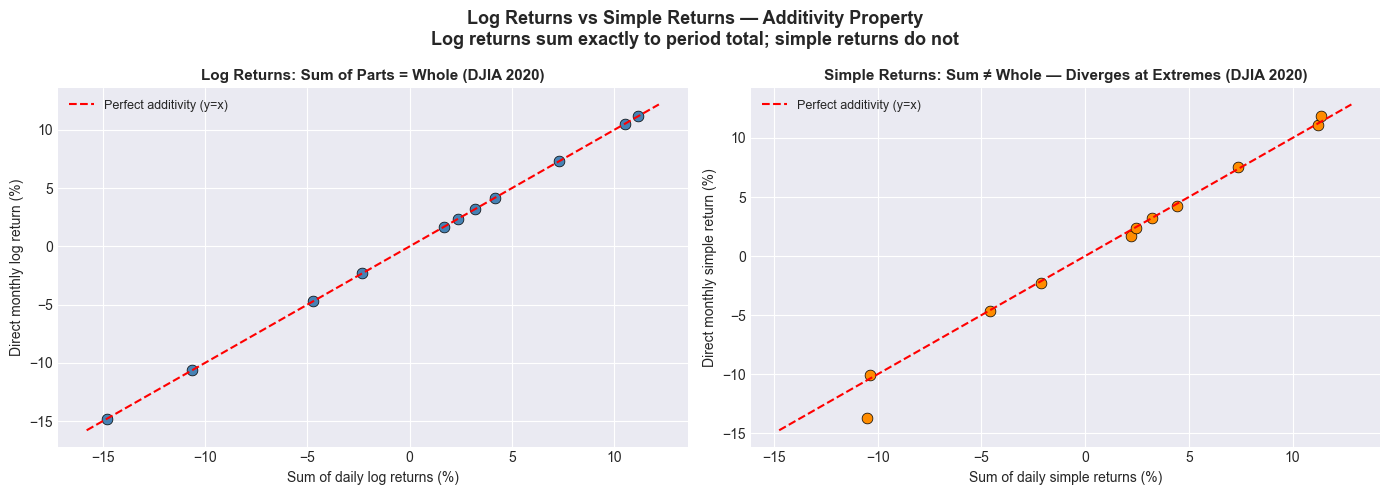

In [9]:
"""
Market Statistical Analysis — Replicating Sornette's "Why Stock Markets Crash"
===============================================================================
Experiments covered:
    1. Return distributions (DJIA vs Nasdaq) with fat-tail fitting
    2. Correlation function of daily returns — decay to zero
    3. Correlation function of monthly returns
    4. Self-similar scaling validation (sqrt of time law)
    5. Volatility clustering across scales
    6. Log returns vs simple returns additivity
    7. Bubble detection — long-range correlation buildup

Requirements:
    pip install yfinance pandas numpy matplotlib scipy
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from scipy.optimize import curve_fit
import warnings
warnings.filterwarnings("ignore")

# ── OUTPUT FOLDER ──────────────────────────────────────────────────────────────
OUTPUT_DIR = "corr&returns_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

try:
    import yfinance as yf
except ImportError:
    raise ImportError("Please run: pip install yfinance")


# ── CONFIG ─────────────────────────────────────────────────────────────────────
DJIA_TICKER    = "^DJI"
NASDAQ_TICKER  = "^IXIC"
START_DATE     = "1990-01-01"
END_DATE       = "2024-01-01"
BUBBLE_START   = "1997-01-01"   # Nasdaq bubble window
BUBBLE_END     = "2000-03-10"   # Nasdaq peak
FIG_STYLE      = "seaborn-v0_8-darkgrid"
plt.style.use(FIG_STYLE)


# ── DATA DOWNLOAD ──────────────────────────────────────────────────────────────
def download_data(ticker, start, end):
    print(f"  Downloading {ticker} ...")
    df = yf.download(ticker, start=start, end=end, progress=False)
    close = df["Close"].squeeze().dropna()
    return close


def compute_returns(price_series):
    log_ret   = np.log(price_series / price_series.shift(1)).dropna()
    simp_ret  = price_series.pct_change().dropna()
    return log_ret, simp_ret


def resample_returns(log_ret, freq="ME"):
    """Resample log returns to monthly or weekly by summing (additivity property)."""
    return log_ret.resample(freq).sum().dropna()


# ── CORRELATION FUNCTION ───────────────────────────────────────────────────────
def autocorrelation(series, max_lag=60):
    """Compute autocorrelation of a return series up to max_lag."""
    series = (series - series.mean()) / series.std()
    n      = len(series)
    lags, acf_vals = [], []
    for lag in range(1, max_lag + 1):
        c = np.corrcoef(series[:-lag].values, series[lag:].values)[0, 1]
        lags.append(lag)
        acf_vals.append(c)
    return np.array(lags), np.array(acf_vals)


def autocorrelation_abs(series, max_lag=60):
    """Autocorrelation of |returns| — captures volatility clustering."""
    return autocorrelation(series.abs(), max_lag)


# ── SCALING LAW ────────────────────────────────────────────────────────────────
def scaling_law_test(daily_log_ret):
    """
    Test sqrt(time) scaling.
    Returns dict of {label: (expected_std, actual_std)}
    """
    std_daily   = daily_log_ret.std()

    weekly      = daily_log_ret.resample("W").sum().dropna()
    std_weekly_actual   = weekly.std()
    std_weekly_expected = std_daily * np.sqrt(5)

    monthly     = daily_log_ret.resample("ME").sum().dropna()
    std_monthly_actual   = monthly.std()
    std_monthly_expected = std_daily * np.sqrt(21)

    quarterly   = daily_log_ret.resample("QE").sum().dropna()
    std_quarterly_actual   = quarterly.std()
    std_quarterly_expected = std_daily * np.sqrt(63)

    return {
        "Daily (baseline)":    (std_daily,              std_daily),
        "Weekly  (√5  days)":  (std_weekly_expected,    std_weekly_actual),
        "Monthly (√21 days)":  (std_monthly_expected,   std_monthly_actual),
        "Quarterly(√63 days)": (std_quarterly_expected, std_quarterly_actual),
    }


# ── DISTRIBUTION FITTING ───────────────────────────────────────────────────────
def ccdf_counts(arr):
    """Return sorted values and count of observations >= each value (raw counts, not probability)."""
    arr_s = np.sort(arr)
    counts = np.arange(len(arr_s), 0, -1)  # N, N-1, ..., 1
    return arr_s, counts


def fit_exponential(x, a, b):
    return a * np.exp(-b * x)


def plot_book_distribution(ax, djia_ret, nasdaq_ret):
    """
    Replicate Figure 2.7 exactly:
    - Y axis: raw count of observations >= x  (log scale)
    - X axis: |return| (linear scale)
    - 4 series: DJ>0, DJ<0, NAS>0, NAS<0
    - Fitted lines for each series
    """
    r_dj  = djia_ret.dropna().values
    r_nas = nasdaq_ret.dropna().values

    series = {
        "return DJ>0":  (r_dj[r_dj   >  0],    "black",  "+",  "-"),
        "return DJ<0":  (-r_dj[r_dj  <  0],    "black",  "o",  "-"),
        "return NAS>0": (r_nas[r_nas  >  0],   "gray",   "x",  "--"),
        "return NAS<0": (-r_nas[r_nas <  0],   "gray",   "D",  "--"),
    }

    for label, (arr, color, marker, linestyle) in series.items():
        x, counts = ccdf_counts(arr)

        # Plot empirical points — subsample for clarity at dense region
        step = max(1, len(x) // 300)
        ax.plot(x[::step], counts[::step],
                marker=marker, linestyle="none",
                color=color, markersize=4, alpha=0.7, label=label)

        # Fit exponential to tail (x > median) and plot fitted line
        try:
            mask = x > np.median(x)
            popt, _ = curve_fit(fit_exponential, x[mask], counts[mask],
                                p0=[counts[mask][0], 50], maxfev=5000)
            x_fit = np.linspace(x[mask][0], x.max(), 200)
            ax.plot(x_fit, fit_exponential(x_fit, *popt),
                    color=color, linestyle=linestyle, lw=1.5, alpha=0.9)
        except Exception:
            pass

    ax.set_yscale("log")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=1)
    ax.set_xlabel("|Returns|", fontsize=12)
    ax.set_ylabel("Distribution Function", fontsize=12)
    ax.set_title("Distribution of Daily Returns — DJIA & Nasdaq\n(Replicating Fig 2.7)",
                 fontsize=12, fontweight="bold")
    ax.legend(fontsize=9, loc="upper right")

    # Reference lines matching the book
    ax.axhline(y=10,  color="black", lw=0.8, linestyle="-", alpha=0.3)
    ax.axhline(y=100, color="black", lw=0.8, linestyle="-", alpha=0.3)


# ── LONG-RANGE CORRELATION (BUBBLE) ───────────────────────────────────────────
def rolling_correlation(series, window=120):
    """
    Long-range correlation buildup measure — replicating Sornette's cooperativity concept.

    Uses:
      - 120-day rolling window: responsive enough to catch buildup BEFORE the peak,
        smooth enough to filter daily noise
      - Absolute returns (|r|) to capture volatility clustering and systemic risk
      - Extended lags 1-20 to detect long-range rather than short-range dependence
      - Light 10-day smoothing to preserve responsiveness while removing noise
    """
    abs_series = series.abs()

    def mean_abs_acf(x):
        if len(x) < 30:
            return np.nan
        x = (x - x.mean()) / (x.std() + 1e-10)
        acf_vals = []
        for l in range(1, 21):
            if l < len(x):
                c = np.corrcoef(x[:-l], x[l:])[0, 1]
                acf_vals.append(abs(c))
        return np.mean(acf_vals) if acf_vals else np.nan

    raw = abs_series.rolling(window).apply(mean_abs_acf, raw=True)
    # Light 10-day smoothing — preserves responsiveness, removes noise
    return raw.rolling(10, min_periods=1).mean()


# ══════════════════════════════════════════════════════════════════════════════
#  MAIN
# ══════════════════════════════════════════════════════════════════════════════
def main():

    print("\n── Downloading data ──")
    djia_price   = download_data(DJIA_TICKER,   START_DATE, END_DATE)
    nasdaq_price = download_data(NASDAQ_TICKER, START_DATE, END_DATE)

    djia_log,   djia_simp   = compute_returns(djia_price)
    nasdaq_log, nasdaq_simp = compute_returns(nasdaq_price)

    djia_monthly   = resample_returns(djia_log,   "ME")
    nasdaq_monthly = resample_returns(nasdaq_log, "ME")

    # ── SCALING LAW RESULTS ────────────────────────────────────────────────────
    print("\n── Scaling Law Test (DJIA) ──")
    djia_scaling = scaling_law_test(djia_log)
    print(f"  {'Scale':<22}  {'Expected σ':>12}  {'Actual σ':>10}  {'Ratio':>8}")
    print(f"  {'-'*56}")
    base_std = djia_log.std()
    for label, (exp, act) in djia_scaling.items():
        ratio = act / base_std
        print(f"  {label:<22}  {exp*100:>11.4f}%  {act*100:>9.4f}%  {ratio:>8.3f}")

    print("\n── Scaling Law Test (Nasdaq) ──")
    nasdaq_scaling = scaling_law_test(nasdaq_log)
    base_std_nq = nasdaq_log.std()
    print(f"  {'Scale':<22}  {'Expected σ':>12}  {'Actual σ':>10}  {'Ratio':>8}")
    print(f"  {'-'*56}")
    for label, (exp, act) in nasdaq_scaling.items():
        ratio = act / base_std_nq
        print(f"  {label:<22}  {exp*100:>11.4f}%  {act*100:>9.4f}%  {ratio:>8.3f}")

    # ══════════════════════════════════════════════════════════════════════════
    #  FIGURE 1 — Return Distributions (replicating Fig 2.7 from book)
    # ══════════════════════════════════════════════════════════════════════════
    fig1, ax = plt.subplots(figsize=(9, 7))
    fig1.suptitle("FIG 2.7 Replica — Distribution of daily returns\n"
                  "DJIA and Nasdaq, January 2 1990 – September 29 2000",
                  fontsize=13, fontweight="bold")

    # Filter to match the book's exact date range
    djia_book   = djia_log["1990-01-02":"2000-09-29"]
    nasdaq_book = nasdaq_log["1990-01-02":"2000-09-29"]

    plot_book_distribution(ax, djia_book, nasdaq_book)

    plt.tight_layout()
    fig1.savefig(os.path.join(OUTPUT_DIR, "fig1_distributions.png"), dpi=150, bbox_inches="tight")
    print("\n  Saved fig1_distributions.png")

    # ══════════════════════════════════════════════════════════════════════════
    #  FIGURE 2 — Autocorrelation of Returns (Daily & Monthly)
    # ══════════════════════════════════════════════════════════════════════════
    fig2, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig2.suptitle("Autocorrelation of Returns — Daily & Monthly\n"
                  "Returns decay to zero fast; |Returns| (volatility) show persistence",
                  fontsize=13, fontweight="bold")

    confidence = 1.96 / np.sqrt(len(djia_log))

    datasets = [
        (djia_log,      "DJIA Daily",   "steelblue",  30),
        (nasdaq_log,    "Nasdaq Daily", "darkorange",  30),
        (djia_monthly,  "DJIA Monthly", "steelblue",   24),
        (nasdaq_monthly,"Nasdaq Monthly","darkorange",  24),
    ]

    for idx, (ser, label, color, max_lag) in enumerate(datasets):
        ax   = axes[idx // 2][idx % 2]
        lags, acf_r   = autocorrelation(ser,     max_lag)
        lags, acf_abs = autocorrelation_abs(ser, max_lag)

        ax.bar(lags, acf_r,   color=color, alpha=0.5, label="Returns ACF",      width=0.4)
        ax.bar(lags + 0.4, acf_abs, color=color, alpha=0.9, label="|Returns| ACF (volatility)", width=0.4)
        ax.axhline(y= confidence, color="k", linestyle="--", lw=0.8, alpha=0.6)
        ax.axhline(y=-confidence, color="k", linestyle="--", lw=0.8, alpha=0.6)
        ax.axhline(y=0,           color="k", lw=0.8)
        ax.set_title(f"{label} Autocorrelation", fontsize=11, fontweight="bold")
        ax.set_xlabel("Lag (periods)", fontsize=10)
        ax.set_ylabel("Autocorrelation", fontsize=10)
        ax.legend(fontsize=9)
        ax.set_ylim(-0.15, 0.25)

        # Annotate key finding
        ax.annotate("Returns → 0 fast\n(efficient market)",
                    xy=(5, acf_r[4]), xytext=(15, 0.15),
                    arrowprops=dict(arrowstyle="->", color="gray"),
                    fontsize=8, color="gray")

    plt.tight_layout()
    fig2.savefig(os.path.join(OUTPUT_DIR, "fig2_autocorrelation.png"), dpi=150, bbox_inches="tight")
    print("  Saved fig2_autocorrelation.png")

    # ══════════════════════════════════════════════════════════════════════════
    #  FIGURE 3 — Scaling Law Validation
    # ══════════════════════════════════════════════════════════════════════════
    fig3, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig3.suptitle("Square-Root-of-Time Scaling Law\n"
                  "Actual volatility closely tracks √t prediction across all scales",
                  fontsize=13, fontweight="bold")

    for ax, (log_ret, label, color, scaling) in zip(axes, [
        (djia_log,   "DJIA",   "steelblue",  djia_scaling),
        (nasdaq_log, "Nasdaq", "darkorange", nasdaq_scaling),
    ]):
        labels_s   = list(scaling.keys())
        expected   = [v[0] * 100 for v in scaling.values()]
        actual     = [v[1] * 100 for v in scaling.values()]
        x          = np.arange(len(labels_s))

        bars1 = ax.bar(x - 0.2, expected, 0.4, label="√t Expected σ", color=color, alpha=0.5)
        bars2 = ax.bar(x + 0.2, actual,   0.4, label="Actual σ",       color=color, alpha=0.9)
        ax.set_xticks(x)
        ax.set_xticklabels(labels_s, rotation=15, ha="right", fontsize=9)
        ax.set_ylabel("Volatility (σ) %", fontsize=11)
        ax.set_title(f"{label} — Scaling Law Test", fontsize=12, fontweight="bold")
        ax.legend(fontsize=10)

        # Ratio annotation
        for i, (exp, act) in enumerate(zip(expected, actual)):
            ratio = act / exp if exp > 0 else 0
            ax.text(i, max(exp, act) + 0.01, f"ratio\n{ratio:.2f}",
                    ha="center", fontsize=8, color="darkred")

    plt.tight_layout()
    fig3.savefig(os.path.join(OUTPUT_DIR, "fig3_scaling_law.png"), dpi=150, bbox_inches="tight")
    print("  Saved fig3_scaling_law.png")

    # ══════════════════════════════════════════════════════════════════════════
    #  FIGURE 4 — Volatility Clustering Across Scales
    # ══════════════════════════════════════════════════════════════════════════
    fig4, axes = plt.subplots(3, 2, figsize=(16, 14))
    fig4.suptitle("Volatility Clustering Across Scales — Self-Similarity\n"
                  "Same bursting structure repeats at daily, weekly, monthly scales",
                  fontsize=13, fontweight="bold")

    for col, (log_ret, price, label, color) in enumerate([
        (djia_log,   djia_price,   "DJIA",   "steelblue"),
        (nasdaq_log, nasdaq_price, "Nasdaq", "darkorange"),
    ]):
        weekly_ret  = resample_returns(log_ret, "W")
        monthly_ret = resample_returns(log_ret, "ME")

        for row, (ret, scale_label) in enumerate([
            (log_ret,    "Daily"),
            (weekly_ret, "Weekly"),
            (monthly_ret,"Monthly"),
        ]):
            ax = axes[row][col]
            ax.plot(ret.index, ret.values * 100, color=color, lw=0.6, alpha=0.8)
            ax.axhline(0, color="black", lw=0.5)

            # Highlight extreme moves
            threshold = ret.std() * 3
            extremes  = ret[np.abs(ret) > threshold]
            ax.scatter(extremes.index, extremes.values * 100,
                       color="red", s=15, zorder=5, label="Extreme (>3σ)")

            ax.set_title(f"{label} {scale_label} Returns", fontsize=11, fontweight="bold")
            ax.set_ylabel("Return (%)", fontsize=9)
            if row == 0:
                ax.legend(fontsize=8)

    plt.tight_layout()
    fig4.savefig(os.path.join(OUTPUT_DIR, "fig4_volatility_clustering.png"), dpi=150, bbox_inches="tight")
    print("  Saved fig4_volatility_clustering.png")

    # ══════════════════════════════════════════════════════════════════════════
    #  FIGURE 5 — 2008 Crash: Rolling Pairwise Correlation of DJIA Components
    # ══════════════════════════════════════════════════════════════════════════
    print("\n  Downloading DJIA component stocks for pairwise correlation (2008 crash)...")

    DJIA_COMPONENTS_2008 = [
        "MMM", "AXP", "BA", "CAT", "CVX", "KO", "XOM",
        "GE", "IBM", "MCD", "MRK", "PG", "WMT", "JPM", "MSFT"
    ]

    stock_data_2008 = {}
    for ticker in DJIA_COMPONENTS_2008:
        try:
            s = yf.download(ticker, start="2004-01-01", end="2010-01-01",
                            progress=False)["Close"].squeeze().dropna()
            if len(s) > 100:
                stock_data_2008[ticker] = np.log(s / s.shift(1)).dropna()
                print(f"    ✓ {ticker}")
        except Exception:
            print(f"    ✗ {ticker} skipped")

    returns_2008 = pd.DataFrame(stock_data_2008).dropna()
    print(f"  Using {returns_2008.shape[1]} stocks, {returns_2008.shape[0]} trading days")

    ROLL_WINDOW_2008 = 60

    def avg_pairwise_corr(df_window):
        """Average of all unique pairwise correlations in the window."""
        corr_matrix = df_window.corr()
        upper = corr_matrix.where(
            np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
        )
        vals = upper.stack().values
        return vals.mean() if len(vals) > 0 else np.nan

    print("  Computing rolling pairwise correlations...")
    roll_pw = pd.Series(index=returns_2008.index, dtype=float)
    for i in range(ROLL_WINDOW_2008, len(returns_2008)):
        roll_pw.iloc[i] = avg_pairwise_corr(returns_2008.iloc[i - ROLL_WINDOW_2008:i])

    roll_pw        = roll_pw.dropna()
    roll_pw_smooth = roll_pw.rolling(10, min_periods=1).mean()

    djia_2008      = download_data(DJIA_TICKER, "2004-01-01", "2010-01-01")

    BUBBLE_2008_START = "2006-01-01"
    DJIA_2008_PEAK    = "2007-10-09"
    CRASH_BOTTOM      = "2009-03-09"

    fig5, axes = plt.subplots(2, 1, figsize=(14, 10))
    fig5.suptitle("2008 Crash — Rolling Average Pairwise Correlation (DJIA)\n"
                  "Rising stock synchronisation signals growing systemic risk before collapse",
                  fontsize=13, fontweight="bold")

    # Top — DJIA price
    ax1 = axes[0]
    ax1.plot(djia_2008.index, djia_2008.values, color="steelblue", lw=1.5)
    ax1.axvspan(pd.Timestamp(BUBBLE_2008_START), pd.Timestamp(DJIA_2008_PEAK),
                alpha=0.15, color="red", label="Bubble buildup")
    ax1.axvspan(pd.Timestamp(DJIA_2008_PEAK), pd.Timestamp(CRASH_BOTTOM),
                alpha=0.15, color="darkred", label="Crash & decline")
    ax1.axvline(pd.Timestamp(DJIA_2008_PEAK), color="red", lw=1.5,
                linestyle="--", label="DJIA Peak (Oct 9, 2007)")
    ax1.axvline(pd.Timestamp(CRASH_BOTTOM), color="darkred", lw=1.5,
                linestyle="--", label="Market Bottom (Mar 9, 2009)")
    ax1.set_title("DJIA Price — 2008 Bubble and Crash", fontsize=12, fontweight="bold")
    ax1.set_ylabel("Index Level", fontsize=10)
    ax1.legend(fontsize=9)

    # Bottom — pairwise correlation
    ax2 = axes[1]
    ax2.plot(roll_pw_smooth.index, roll_pw_smooth.values,
             color="steelblue", lw=1.5,
             label=f"Avg pairwise correlation ({ROLL_WINDOW_2008}-day rolling)")
    ax2.axvspan(pd.Timestamp(BUBBLE_2008_START), pd.Timestamp(DJIA_2008_PEAK),
                alpha=0.15, color="red")
    ax2.axvspan(pd.Timestamp(DJIA_2008_PEAK), pd.Timestamp(CRASH_BOTTOM),
                alpha=0.15, color="darkred")
    ax2.axvline(pd.Timestamp(DJIA_2008_PEAK), color="red", lw=1.5,
                linestyle="--", label="DJIA Peak")
    ax2.axvline(pd.Timestamp(CRASH_BOTTOM), color="darkred", lw=1.5,
                linestyle="--", label="Market Bottom")

    # Trend line — pre-peak buildup only
    pre_peak_2008 = roll_pw_smooth[BUBBLE_2008_START:"2007-09-01"].dropna()
    if len(pre_peak_2008) > 10:
        x_num = np.arange(len(pre_peak_2008))
        slope, intercept = np.polyfit(x_num, pre_peak_2008.values, 1)
        trend = slope * x_num + intercept
        ax2.plot(pre_peak_2008.index, trend, color="black", lw=2,
                 linestyle="--", alpha=0.7,
                 label=f"Buildup trend (slope={slope*252:.4f}/yr)")
        mid = len(pre_peak_2008) // 2
        ax2.annotate(
            "Stocks increasingly\nmoving in lockstep\nbefore crash",
            xy=(pre_peak_2008.index[mid], trend[mid]),
            xytext=(pre_peak_2008.index[max(0, mid - 150)],
                    trend[mid] + pre_peak_2008.std() * 1.5),
            arrowprops=dict(arrowstyle="->", color="darkblue", lw=1.5),
            fontsize=9, color="darkblue", fontweight="bold"
        )

    # Annotate the correlation spike at crash peak
    crash_peak_idx = roll_pw_smooth["2008-01-01":"2009-06-01"].idxmax()
    crash_peak_val = roll_pw_smooth[crash_peak_idx]
    ax2.annotate(
        "Correlation spikes\nat crash peak\n(maximum cooperativity)",
        xy=(crash_peak_idx, crash_peak_val),
        xytext=(pd.Timestamp("2008-01-01"),
                crash_peak_val - pre_peak_2008.std() * 1.2),
        arrowprops=dict(arrowstyle="->", color="darkred", lw=1.5),
        fontsize=9, color="darkred", fontweight="bold"
    )

    ax2.set_title("Average Pairwise Correlation of DJIA Components — Cooperativity Measure",
                  fontsize=12, fontweight="bold")
    ax2.set_ylabel("Mean Pairwise Correlation", fontsize=10)
    ax2.set_xlabel("Date", fontsize=10)
    ax2.legend(fontsize=9)

    plt.tight_layout()
    fig5.savefig(os.path.join(OUTPUT_DIR, "fig5_bubble_correlation.png"), dpi=150, bbox_inches="tight")
    print("  Saved fig5_bubble_correlation.png")

    # ══════════════════════════════════════════════════════════════════════════
    #  FIGURE 5b — Pairwise Correlation Heatmaps at 3 Key Snapshots
    #  Pre-bubble / Pre-crash peak / During crash
    # ══════════════════════════════════════════════════════════════════════════
    snapshots = [
        ("Pre-Bubble\n(Jan 2006)",       "2005-07-01", "2006-01-01",  "Blues"),
        ("Pre-Crash Peak\n(Oct 2007)",   "2007-04-01", "2007-10-09",  "Oranges"),
        ("During Crash\n(Oct 2008)",     "2008-04-01", "2008-10-01",  "Reds"),
    ]

    fig5b, axes5b = plt.subplots(1, 3, figsize=(18, 6))
    fig5b.suptitle("Pairwise Correlation Heatmaps — DJIA Components at Key Moments\n"
                   "Deeper colour = higher correlation = more lockstep movement",
                   fontsize=13, fontweight="bold")

    for ax, (label, start, end, cmap) in zip(axes5b, snapshots):
        window_df   = returns_2008[start:end]
        corr_matrix = window_df.corr()
        avg_corr    = corr_matrix.where(
            np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
        ).stack().mean()

        im = ax.imshow(corr_matrix.values, cmap=cmap, vmin=0, vmax=1,
                       aspect="auto")
        ax.set_xticks(range(len(corr_matrix.columns)))
        ax.set_yticks(range(len(corr_matrix.index)))
        ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right", fontsize=8)
        ax.set_yticklabels(corr_matrix.index, fontsize=8)
        ax.set_title(f"{label}\nAvg pairwise corr = {avg_corr:.3f}",
                     fontsize=11, fontweight="bold")

        # Annotate each cell with its value
        for i in range(len(corr_matrix)):
            for j in range(len(corr_matrix.columns)):
                val = corr_matrix.values[i, j]
                ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                        fontsize=6,
                        color="white" if val > 0.6 else "black")

        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Correlation")

    plt.tight_layout()
    fig5b.savefig(os.path.join(OUTPUT_DIR, "fig5b_pairwise_heatmaps.png"), dpi=150, bbox_inches="tight")
    print("  Saved fig5b_pairwise_heatmaps.png")
    # ══════════════════════════════════════════════════════════════════════════
    fig6, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig6.suptitle("Log Returns vs Simple Returns — Additivity Property\n"
                  "Log returns sum exactly to period total; simple returns do not",
                  fontsize=13, fontweight="bold")

    sample = djia_log["2020-01-01":"2020-12-31"]
    monthly_sum    = sample.resample("ME").sum()        # summing daily log returns
    monthly_direct = np.log(
        djia_price["2020-01-01":"2020-12-31"].resample("ME").last() /
        djia_price["2020-01-01":"2020-12-31"].resample("ME").last().shift(1)
    ).dropna()

    common = monthly_sum.index.intersection(monthly_direct.index)
    axes[0].scatter(monthly_sum.loc[common] * 100,
                    monthly_direct.loc[common] * 100,
                    color="steelblue", s=60, edgecolors="black", lw=0.5)
    lims = [min(monthly_sum.loc[common].min(), monthly_direct.loc[common].min()) * 100 - 1,
            max(monthly_sum.loc[common].max(), monthly_direct.loc[common].max()) * 100 + 1]
    axes[0].plot(lims, lims, "r--", lw=1.5, label="Perfect additivity (y=x)")
    axes[0].set_xlabel("Sum of daily log returns (%)", fontsize=10)
    axes[0].set_ylabel("Direct monthly log return (%)", fontsize=10)
    axes[0].set_title("Log Returns: Sum of Parts = Whole (DJIA 2020)", fontsize=11, fontweight="bold")
    axes[0].legend(fontsize=9)

    # Simple returns — show they DON'T add
    sample_simp = djia_simp["2020-01-01":"2020-12-31"]
    monthly_simp_sum    = sample_simp.resample("ME").sum()
    monthly_simp_direct = djia_price["2020-01-01":"2020-12-31"].resample("ME").last().pct_change().dropna()

    common2 = monthly_simp_sum.index.intersection(monthly_simp_direct.index)
    axes[1].scatter(monthly_simp_sum.loc[common2] * 100,
                    monthly_simp_direct.loc[common2] * 100,
                    color="darkorange", s=60, edgecolors="black", lw=0.5)
    lims2 = [min(monthly_simp_sum.loc[common2].min(),
                 monthly_simp_direct.loc[common2].min()) * 100 - 1,
             max(monthly_simp_sum.loc[common2].max(),
                 monthly_simp_direct.loc[common2].max()) * 100 + 1]
    axes[1].plot(lims2, lims2, "r--", lw=1.5, label="Perfect additivity (y=x)")
    axes[1].set_xlabel("Sum of daily simple returns (%)", fontsize=10)
    axes[1].set_ylabel("Direct monthly simple return (%)", fontsize=10)
    axes[1].set_title("Simple Returns: Sum ≠ Whole — Diverges at Extremes (DJIA 2020)",
                      fontsize=11, fontweight="bold")
    axes[1].legend(fontsize=9)

    plt.tight_layout()
    fig6.savefig(os.path.join(OUTPUT_DIR, "fig6_log_vs_simple.png"), dpi=150, bbox_inches="tight")
    print("  Saved fig6_log_vs_simple.png")

    print(f"\n✓ All figures saved to folder: {OUTPUT_DIR}/")
    print("  fig1_distributions.png          — Fat tail return distributions")
    print("  fig2_autocorrelation.png        — Correlation decay (daily & monthly)")
    print("  fig3_scaling_law.png            — Square-root-of-time scaling")
    print("  fig4_volatility_clustering.png  — Self-similar volatility bursts")
    print("  fig5_bubble_correlation.png     — Rolling pairwise correlation (2008)")
    print("  fig5b_pairwise_heatmaps.png     — Pairwise heatmaps at 3 key snapshots")
    print("  fig6_log_vs_simple.png          — Log vs simple return additivity")


if __name__ == "__main__":
    main()